--- Summary Statistics (Lead levels in ppb) ---
                         source      Mean  Median   P90   Max  Count
             MDEQ (All Samples)  7.309859   3.000 18.00 104.0     71
     MDEQ (Filtered / Excluded)  5.724638   3.000 11.40  42.0     69
Virginia Tech (Citizen Science) 10.645993   3.521 26.64 158.0    271


/tmp/ipykernel_477/3644519203.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


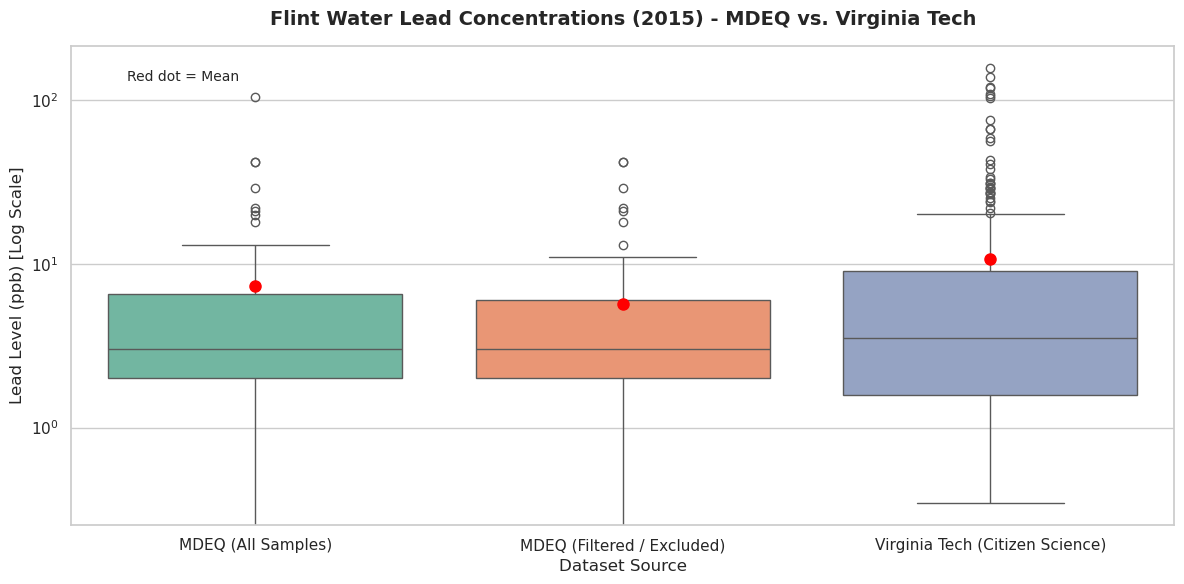

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load the data directly from the TidyTuesday GitHub repository
url_mdeq = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-11-04/flint_mdeq.csv"
url_vt = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-11-04/flint_vt.csv"

flint_mdeq = pd.read_csv(url_mdeq)
flint_vt = pd.read_csv(url_vt)

# 2. Data Preparation: Combine datasets for a side-by-side distribution plot
# We'll create a source label for each
flint_mdeq["source"] = "MDEQ (All Samples)"
flint_vt["source"] = "Virginia Tech (Citizen Science)"

# For MDEQ with excluded samples (lead2 column handles removed samples)
flint_mdeq_filtered = flint_mdeq.copy()
flint_mdeq_filtered["lead"] = flint_mdeq_filtered[
    "lead2"
]  # use filtered lead column
flint_mdeq_filtered["source"] = "MDEQ (Filtered / Excluded)"

# Combine MDEQ (all), MDEQ (filtered), and VT for comparison
combined_df = pd.concat(
    [
        flint_mdeq[["lead", "source"]],
        flint_mdeq_filtered[["lead", "source"]],
        flint_vt[["lead", "source"]],
    ]
)

# Drop missing values if any
combined_df = combined_df.dropna(subset=["lead"])

# 3. Print out key comparative statistics
print("--- Summary Statistics (Lead levels in ppb) ---")
stats = (
    combined_df.groupby("source")["lead"]
    .agg(
        Mean="mean",
        Median="median",
        P90=lambda x: x.quantile(0.90),
        Max="max",
        Count="count",
    )
    .reset_index()
)
print(stats.to_string(index=False))

# 4. Plotting the distribution (using a log scale due to high skewness in lead levels)
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Create a boxplot / stripplot or violin plot to compare distributions
ax = sns.boxplot(
    data=combined_df,
    x="source",
    y="lead",
    palette="Set2",
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
        "markersize": "8",
    },
)

# Use log scale on Y-axis because lead concentrations vary by orders of magnitude
ax.set_yscale("log")
plt.title(
    "Flint Water Lead Concentrations (2015) - MDEQ vs. Virginia Tech",
    fontsize=14,
    weight="bold",
    pad=15,
)
plt.xlabel("Dataset Source", fontsize=12)
plt.ylabel("Lead Level (ppb) [Log Scale]", fontsize=12)

# Annotate mean marker legend
plt.text(
    0.05,
    0.95,
    "Red dot = Mean",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
)

plt.tight_layout()
plt.show()